# Chapitre 4 - Méthodes linéaires de classification
## Cours 3 : régression logistique et hyperplans séparateurs

Ce notebook couvre les sections 4.4 et 4.5 du livre :

1. le **modèle logistique** et son ajustement par maximum de vraisemblance via
   l'algorithme de **Newton-Raphson**, qui prend la forme de **moindres carrés pondérés
   itérés** (IRLS) ;
2. l'exemple des **maladies cardiaques en Afrique du Sud** (figure 4.12, tableaux 4.2 et
   4.3) et l'inférence associée ;
3. la **régression logistique pénalisée L1** (figure 4.13) ;
4. la comparaison LDA / logistique ;
5. les **hyperplans séparateurs** : perceptron de Rosenblatt (figure 4.14) et hyperplan
   séparateur optimal (figure 4.16).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

## 1. Le modèle logistique (section 4.4)

On modélise directement les probabilités a posteriori $\Pr(G = k \mid X = x)$ par des
fonctions de $x$ dont les **log-rapports** à une classe de référence (la dernière) sont
affines (éq. (4.17) du livre) :
$$\log\frac{\Pr(G=k\mid X=x)}{\Pr(G=K\mid X=x)} = \beta_{k0} + \beta_k^Tx, \qquad k = 1,\dots,K-1.$$

En exponentiant et en imposant que les $K$ probabilités somment à 1, on obtient
(éq. (4.18)) :
$$\Pr(G=k\mid X=x) = \frac{\exp(\beta_{k0}+\beta_k^Tx)}{1+\sum_{\ell=1}^{K-1}\exp(\beta_{\ell 0}+\beta_\ell^Tx)}
\quad (k<K), \qquad
\Pr(G=K\mid X=x) = \frac{1}{1+\sum_{\ell=1}^{K-1}\exp(\beta_{\ell 0}+\beta_\ell^Tx)}.$$
Ces quantités sont bien positives et de somme 1. Le choix de la classe de référence est
arbitraire : les estimations des probabilités n'en dépendent pas.

**Deux classes.** On code la réponse $y_i = 1$ pour la classe 1 et $y_i = 0$ pour la
classe 2, et on note $p(x;\beta) = \Pr(G=1\mid X=x)$. Avec $x$ complété d'un 1 initial
(pour la constante) et $\beta = (\beta_{10}, \beta_1)$ :
$$p(x;\beta) = \sigma(\beta^Tx), \qquad \sigma(t) = \frac{e^t}{1+e^t} \quad\text{(fonction sigmoïde)}.$$

### Vraisemblance

Les $y_i$ étant des variables de Bernoulli indépendantes (conditionnellement aux $x_i$)
de paramètres $p(x_i;\beta)$, la log-vraisemblance vaut (éq. (4.20))
$$\ell(\beta) = \sum_{i=1}^N\Big[y_i\log p(x_i;\beta) + (1-y_i)\log(1-p(x_i;\beta))\Big]
= \sum_{i=1}^N\Big[y_i\beta^Tx_i - \log\big(1+e^{\beta^Tx_i}\big)\Big].$$
Pour la seconde forme, on a utilisé $\log p = \beta^Tx - \log(1+e^{\beta^Tx})$ et
$\log(1-p) = -\log(1+e^{\beta^Tx})$.

### Gradient et hessienne

On dérive terme à terme. Comme $\frac{d}{dt}\log(1+e^t) = \sigma(t)$, et par la règle de
dérivation composée,
$$\frac{\partial\ell}{\partial\beta} = \sum_{i=1}^N x_i\big(y_i - p(x_i;\beta)\big)
\qquad\text{(éq. (4.21))}.$$
En dérivant encore, avec $\sigma'(t) = \sigma(t)(1-\sigma(t))$ :
$$\frac{\partial^2\ell}{\partial\beta\,\partial\beta^T} = -\sum_{i=1}^N x_ix_i^T\,p(x_i;\beta)\big(1-p(x_i;\beta)\big)
\qquad\text{(éq. (4.22))}.$$

> **Concavité.** Pour tout vecteur $v$, $v^T\big(\partial^2\ell\big)v = -\sum_i p_i(1-p_i)(v^Tx_i)^2 \le 0$ :
> la hessienne est semi-définie négative, donc $\ell$ est **concave**. Un point où le
> gradient s'annule est un maximum global ; il est unique si $\mathbf{X}$ est de rang plein
> et si ce maximum existe (il n'existe pas toujours : voir l'exercice 4.5).

### Newton-Raphson et moindres carrés pondérés itérés

L'algorithme de Newton remplace $\ell$ par son développement de Taylor d'ordre 2 autour de
l'itéré courant et maximise cette approximation quadratique (éq. (4.23)) :
$$\beta^{\text{new}} = \beta^{\text{old}} - \Big(\frac{\partial^2\ell}{\partial\beta\,\partial\beta^T}\Big)^{-1}\frac{\partial\ell}{\partial\beta}.$$
En notation matricielle, avec $\mathbf{p}$ le vecteur des $p(x_i;\beta^{\text{old}})$ et
$\mathbf{W} = \operatorname{diag}\big(p_i(1-p_i)\big)$, le gradient vaut
$\mathbf{X}^T(\mathbf{y}-\mathbf{p})$ et la hessienne $-\mathbf{X}^T\mathbf{W}\mathbf{X}$.

Le pas de Newton se réécrit (éq. (4.26)) :
$$\begin{aligned}
\beta^{\text{new}} &= \beta^{\text{old}} + (\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^T(\mathbf{y}-\mathbf{p}) \\
&= (\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^T\mathbf{W}\big(\mathbf{X}\beta^{\text{old}} + \mathbf{W}^{-1}(\mathbf{y}-\mathbf{p})\big)
= (\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^T\mathbf{W}\mathbf{z},
\end{aligned}$$
où l'on a factorisé $(\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^T\mathbf{W}$ et
introduit la **réponse ajustée** $\mathbf{z} = \mathbf{X}\beta^{\text{old}} + \mathbf{W}^{-1}(\mathbf{y}-\mathbf{p})$.

On reconnaît la solution des **moindres carrés pondérés**
$\beta^{\text{new}} = \operatorname*{arg\,min}_\beta (\mathbf{z}-\mathbf{X}\beta)^T\mathbf{W}(\mathbf{z}-\mathbf{X}\beta)$
(éq. (4.28)). Comme $\mathbf{p}$, $\mathbf{W}$ et $\mathbf{z}$ changent à chaque itération,
on parle de **moindres carrés pondérés itérés** (IRLS). On part en général de $\beta = 0$ ;
la convergence n'est pas garantie en théorie (la log-vraisemblance étant concave, elle
l'est presque toujours en pratique ; sinon on réduit le pas).

## 2. Exemple : maladies cardiaques en Afrique du Sud (section 4.4.2)

Les données proviennent d'une enquête sur les facteurs de risque coronarien dans trois
régions rurales du Cap-Occidental. La réponse `chd` indique un infarctus du myocarde
(160 cas, 302 témoins). Les prédicteurs : pression systolique `sbp`, tabac cumulé en kg
`tobacco`, cholestérol LDL `ldl`, `adiposity`, antécédents familiaux `famhist` (0/1),
score de comportement de type A `typea`, `obesity`, `alcohol` et `age`.

In [2]:
sa = datasets.load_saheart()
print(sa.shape)
sa.head()

(462, 10)


,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
1,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
2,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
3,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
4,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


La figure 4.12 du livre est une matrice de nuages de points, les cas en orange et les
témoins en bleu.

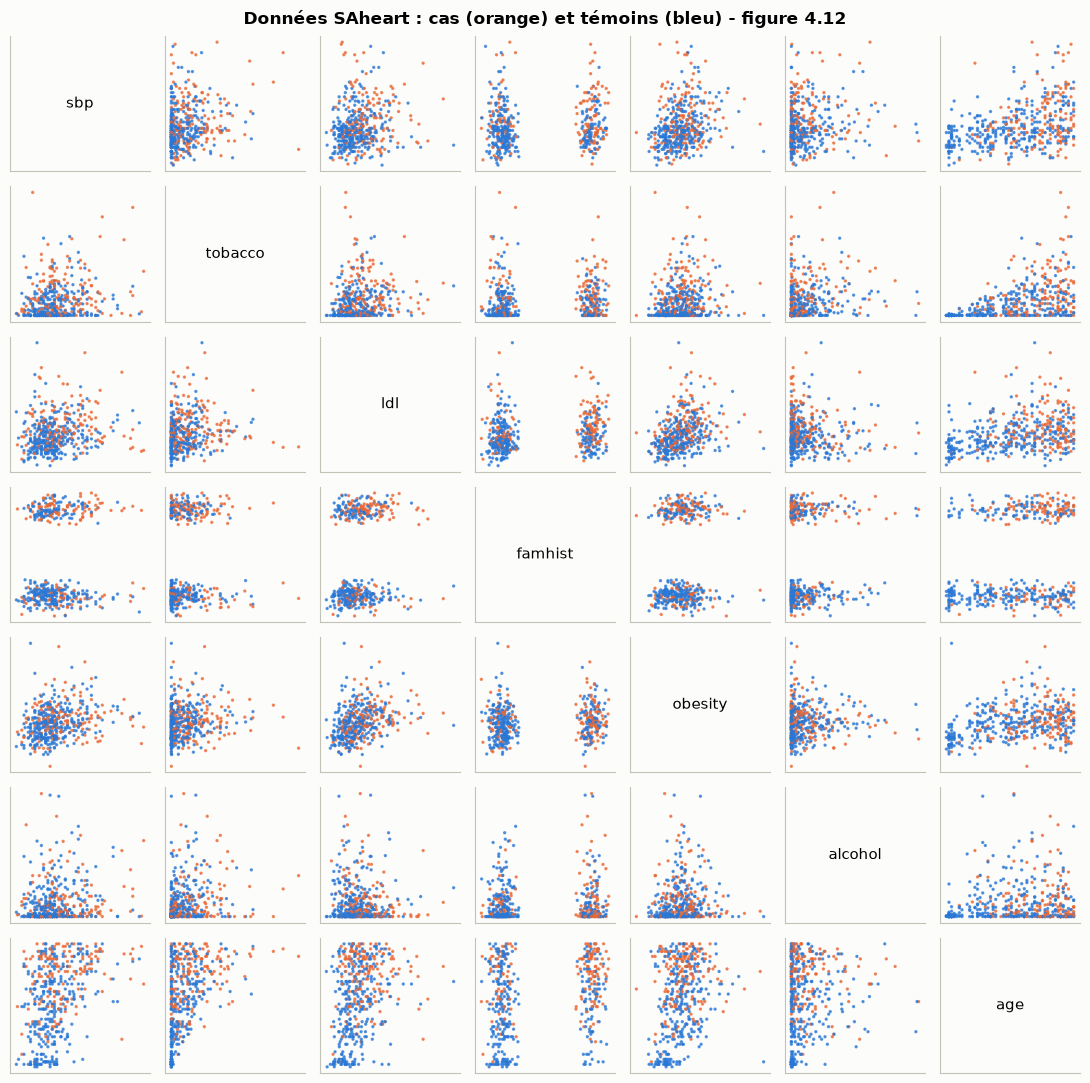

In [3]:
vars_all = ["sbp", "tobacco", "ldl", "famhist", "obesity", "alcohol", "age"]
n = len(vars_all)
col = np.where(sa["chd"] == 1, ORANGE, BLUE)
fig, axes = plt.subplots(n, n, figsize=(11, 11))
for i, vi in enumerate(vars_all):
    for j, vj in enumerate(vars_all):
        ax = axes[i, j]
        ax.grid(False)
        if i == j:
            ax.text(0.5, 0.5, vi, ha="center", va="center", fontsize=11, transform=ax.transAxes)
        else:
            jitter = 0.08 * np.random.RandomState(0).randn(len(sa)) if "famhist" in (vi, vj) else 0
            xj = sa[vj] + (jitter if vj == "famhist" else 0)
            yi = sa[vi] + (jitter if vi == "famhist" else 0)
            ax.scatter(xj, yi, s=2, c=col, alpha=0.7)
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Données SAheart : cas (orange) et témoins (bleu) - figure 4.12", fontweight="bold")
fig.tight_layout()
plt.show()

### Ajustement par IRLS (tableau 4.2)

Comme dans le livre, on retient les 7 prédicteurs ci-dessus. La fonction `logistic_irls`
du module implémente exactement l'itération (4.26)-(4.28) ; elle renvoie aussi les
erreurs standard, racines des éléments diagonaux de $(\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}$
évalué en $\hat\beta$ (voir la section 2.2 ci-dessous).

In [4]:
Xsa = sa[vars_all].to_numpy(float)
ysa = sa["chd"].to_numpy(float)
fit = c4.logistic_irls(Xsa, ysa)
print("Nombre d'itérations :", fit["n_iter"])
print("Log-vraisemblance au fil des itérations :", np.round(fit["history"], 4))

Nombre d'itérations : 6
Log-vraisemblance au fil des itérations : [-320.234  -245.7973 -241.7024 -241.5872 -241.587  -241.587  -241.587 ]


In [5]:
table42 = pd.DataFrame({"coefficient": fit["coef"], "erreur std.": fit["se"], "score Z": fit["z"]},
                       index=["(constante)"] + vars_all).round(3)
table42

,coefficient,erreur std.,score Z
(constante),-4.130,0.964,-4.283
sbp,0.006,0.006,1.023
tobacco,0.080,0.026,3.034
ldl,0.185,0.057,3.218
famhist,0.939,0.225,4.177
obesity,-0.035,0.029,-1.187
alcohol,0.001,0.004,0.136
age,0.043,0.010,4.181


Nous retrouvons le tableau 4.2 du livre (constante $-4{,}130$, `famhist` $0{,}939$,
`age` $0{,}043$, etc.). Comparons à l'implémentation de scikit-learn (sans pénalité),
simplement pour contrôle.

In [6]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-10).fit(Xsa, ysa)
print("Écart maximal avec scikit-learn : %.1e" % np.max(np.abs(np.r_[sk.intercept_, sk.coef_[0]] - fit["coef"])))

Écart maximal avec scikit-learn : 1.5e-07


**Convergence quadratique.** L'algorithme de Newton converge très vite près de
l'optimum : le nombre de chiffres exacts double à peu près à chaque itération.

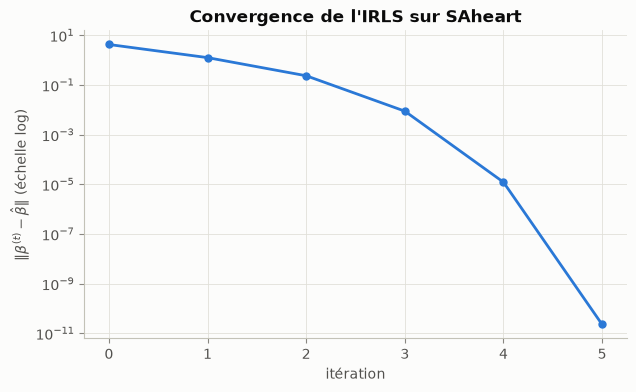

In [7]:
path = fit["coef_path"]
dist = np.linalg.norm(path - fit["coef"], axis=1)[:-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(len(dist)), dist, "o-", color=BLUE)
ax.set_title("Convergence de l'IRLS sur SAheart")
ax.set_xlabel("itération")
ax.set_ylabel(r"$\|\beta^{(t)} - \hat\beta\|$ (échelle log)")
plt.show()

### Lecture du tableau

Le **score Z** est le coefficient divisé par son erreur standard. Sous l'hypothèse
$\beta_j = 0$ (les autres coefficients étant libres), il suit approximativement une loi
$\mathcal{N}(0,1)$ : c'est le **test de Wald**. Un $|Z| > 2$ environ est significatif au
niveau 5 %.

Surprise : `sbp` n'est pas significatif et `obesity` a un coefficient **négatif**. C'est un
effet des **corrélations** entre prédicteurs : prises isolément, ces variables sont bien
significatives et de signe positif.

In [8]:
for v in ["sbp", "obesity"]:
    f1 = c4.logistic_irls(sa[[v]].to_numpy(float), ysa)
    print("%-8s seul : coefficient %.4f, Z = %.2f" % (v, f1["coef"][1], f1["z"][1]))
print("Corrélations avec age :", sa[["sbp", "obesity"]].corrwith(sa["age"]).round(2).to_dict())

sbp      seul : coefficient 0.0195, Z = 4.01
obesity  seul : coefficient 0.0494, Z = 2.13
Corrélations avec age : {'sbp': 0.39, 'obesity': 0.29}


### Sélection de variables (tableau 4.3)

On élimine itérativement la variable de plus petit $|Z|$ et on réajuste, jusqu'à ce que
toutes les variables restantes soient significatives ($|Z| \ge 2$).

In [9]:
retenues = list(vars_all)
while True:
    f = c4.logistic_irls(sa[retenues].to_numpy(float), ysa)
    j = np.argmin(np.abs(f["z"][1:]))
    if abs(f["z"][1 + j]) >= 2:
        break
    print("on retire %-8s (Z = %+.2f)" % (retenues[j], f["z"][1 + j]))
    retenues.pop(j)
table43 = pd.DataFrame({"coefficient": f["coef"], "erreur std.": f["se"], "score Z": f["z"]},
                       index=["(constante)"] + retenues).round(3)
table43

on retire alcohol  (Z = +0.14)
on retire sbp      (Z = +1.05)
on retire obesity  (Z = -1.06)


,coefficient,erreur std.,score Z
(constante),-4.204,0.498,-8.436
tobacco,0.081,0.026,3.163
ldl,0.168,0.054,3.093
famhist,0.924,0.223,4.141
age,0.044,0.010,4.520


On retrouve le modèle du tableau 4.3 (`tobacco`, `ldl`, `famhist`, `age`).

Une stratégie plus coûteuse mais préférable compare les **déviances**. La déviance d'un
modèle est $-2\ell(\hat\beta)$ ; la différence de déviance entre un modèle et un sous-modèle
ayant une variable de moins suit approximativement un $\chi^2_1$ si la variable est inutile.
On retire à chaque étape la variable dont le retrait augmente le moins la déviance, tant
que cette augmentation n'est pas significative ($< 3{,}84$, quantile 95 % du $\chi^2_1$).

In [10]:
retenues_dev = list(vars_all)
dev = c4.logistic_irls(sa[retenues_dev].to_numpy(float), ysa)["deviance"]
while len(retenues_dev) > 1:
    hausses = [c4.logistic_irls(sa[[v for v in retenues_dev if v != w]].to_numpy(float), ysa)["deviance"] - dev
               for w in retenues_dev]
    j = int(np.argmin(hausses))
    if hausses[j] >= stats.chi2.ppf(0.95, 1):
        break
    print("on retire %-8s (hausse de déviance %.2f)" % (retenues_dev[j], hausses[j]))
    dev += hausses[j]
    retenues_dev.pop(j)
print("Modèle final :", retenues_dev)

on retire alcohol  (hausse de déviance 0.02)
on retire sbp      (hausse de déviance 1.10)
on retire obesity  (hausse de déviance 1.15)
Modèle final : ['tobacco', 'ldl', 'famhist', 'age']


Les deux stratégies conduisent au même modèle final, comme l'indique le livre.

**Interprétation d'un coefficient.** Le coefficient de `tobacco` vaut $0{,}081$ : une
augmentation de 1 kg de tabac consommé au cours de la vie multiplie la **cote**
(*odds*) $p/(1-p)$ de maladie coronarienne par $e^{0{,}081}\approx 1{,}084$, soit $+8{,}4\,\%$.
Un intervalle de confiance approché à 95 % s'obtient par $\exp(\hat\beta \pm 2\,\widehat{\text{se}})$.

In [11]:
b, s = table43.loc["tobacco", "coefficient"], table43.loc["tobacco", "erreur std."]
print("Rapport de cotes : %.3f ; IC à 95 %% : (%.2f, %.2f)" % (np.exp(b), np.exp(b - 2 * s), np.exp(b + 2 * s)))

Rapport de cotes : 1.084 ; IC à 95 % : (1.03, 1.14)


## 2.2 Approximations quadratiques et inférence (section 4.4.3)

À la convergence, $\hat\beta$ est la solution d'un problème de moindres carrés pondérés.
Cela donne plusieurs résultats utiles :

- la **déviance** est approchée par la somme pondérée des carrés des résidus,
  $\sum_i (y_i-\hat p_i)^2/(\hat p_i(1-\hat p_i))$ : c'est la statistique du $\chi^2$ de
  Pearson (éq. (4.30)) ;
- par la théorie asymptotique du maximum de vraisemblance, si le modèle est correct,
  $\hat\beta$ est approximativement $\mathcal{N}\big(\beta, (\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\big)$.

Vérifions le second point par simulation : on prend le modèle ajusté comme « vrai »
modèle, on simule 300 nouveaux vecteurs de réponses, on réajuste à chaque fois, et on
compare les écarts types empiriques des $\hat\beta_j$ aux erreurs standard théoriques.

In [12]:
rng = np.random.RandomState(0)
p_vrai = c4.logistic_predict_proba(fit["coef"], Xsa)
betas = np.array([c4.logistic_irls(Xsa, (rng.rand(len(ysa)) < p_vrai).astype(float))["coef"]
                  for _ in range(300)])
comp = pd.DataFrame({"écart type simulé": betas.std(axis=0), "erreur std. théorique": fit["se"]},
                    index=["(constante)"] + vars_all).round(4)
comp

,écart type simulé,erreur std. théorique
(constante),1.0158,0.9642
sbp,0.0060,0.0056
tobacco,0.0259,0.0262
ldl,0.0621,0.0574
famhist,0.2141,0.2249
obesity,0.0293,0.0291
alcohol,0.0044,0.0045
age,0.0103,0.0102


In [13]:
pearson = np.sum((ysa - p_vrai) ** 2 / (p_vrai * (1 - p_vrai)))
print("Déviance : %.1f   chi2 de Pearson : %.1f   (N - p - 1 = %d)" % (fit["deviance"], pearson, len(ysa) - 8))

Déviance : 483.2   chi2 de Pearson : 458.6   (N - p - 1 = 454)


Les erreurs standard théoriques sont très proches des écarts types simulés : l'approximation
gaussienne est fiable ici. Déviance et $\chi^2$ de Pearson sont du même ordre.

## 3. Régression logistique pénalisée L1 (section 4.4.4)

Comme pour le lasso (chapitre 3), on peut pénaliser la norme $\ell_1$ des coefficients
pour obtenir à la fois sélection de variables et rétrécissement (éq. (4.31)) :
$$\max_{\beta_0,\beta}\ \Big\{\sum_{i=1}^N\big[y_i(\beta_0+\beta^Tx_i) - \log(1+e^{\beta_0+\beta^Tx_i})\big] - \lambda\sum_{j=1}^p|\beta_j|\Big\}.$$
La constante n'est pas pénalisée, et les prédicteurs sont standardisés. Dans le code, nous
divisons la log-vraisemblance par $N$, ce qui change seulement l'échelle de $\lambda$.

### Outil : sous-gradient de la valeur absolue

La fonction $t\mapsto|t|$ n'est pas dérivable en 0. On remplace sa dérivée par
l'ensemble des « pentes admissibles » en ce point, appelé **sous-différentiel** :
$$\partial|t| = \{\operatorname{sign}(t)\}\ \text{si } t\ne 0, \qquad \partial|0| = [-1, 1].$$
Intuition : ce sont les pentes des droites passant par $(0,0)$ et situées sous le graphe de
$|t|$. Pour une fonction concave à maximiser du type « lisse $-\ \lambda|\cdot|$ », la
condition d'optimalité devient « $0$ appartient au sous-différentiel ».

Appliquée ici, cette condition donne (éq. (4.32)) : pour chaque variable **active**
($\hat\beta_j\neq 0$),
$$\mathbf{x}_j^T(\mathbf{y}-\mathbf{p}) = \lambda\operatorname{sign}(\hat\beta_j),$$
et pour chaque variable **inactive**, $|\mathbf{x}_j^T(\mathbf{y}-\mathbf{p})| \le \lambda$.
C'est l'analogue exact de la condition du lasso, avec la « corrélation généralisée »
$\mathbf{x}_j^T(\mathbf{y}-\mathbf{p})$ entre la variable et les résidus.

**Algorithme.** Nous combinons l'IRLS et la descente par coordonnées (comme le
paquet R `glmnet`) : à chaque itération externe, on remplace la log-vraisemblance par son
approximation quadratique (moindres carrés pondérés en $\mathbf{z}$) ; on minimise ce
problème pénalisé coordonnée par coordonnée, chaque mise à jour étant un **seuillage
doux** $S(u,\lambda) = \operatorname{sign}(u)(|u|-\lambda)_+$. On calcule le chemin sur une
grille décroissante de $\lambda$ en partant de la solution précédente (« démarrage à chaud »).

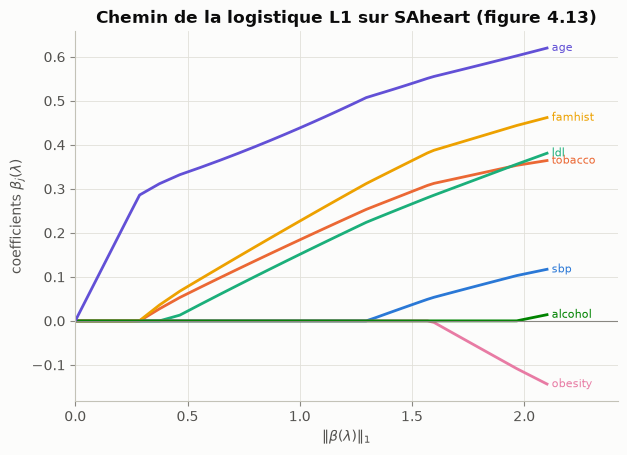

In [14]:
Xs = (Xsa - Xsa.mean(axis=0)) / Xsa.std(axis=0)
lams, coefs = c4.logistic_l1_path(Xs, ysa, n_lambda=80, ratio=1e-3)
norme1 = np.abs(coefs[:, 1:]).sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 4.8))
for j, v in enumerate(vars_all):
    ax.plot(norme1, coefs[:, 1 + j], color=COLORS[j], label=v)
    ax.text(norme1[-1] * 1.01, coefs[-1, 1 + j], v, fontsize=8, va="center", color=COLORS[j])
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_title("Chemin de la logistique L1 sur SAheart (figure 4.13)")
ax.set_xlabel(r"$\|\beta(\lambda)\|_1$")
ax.set_ylabel(r"coefficients $\beta_j(\lambda)$")
ax.set_xlim(0, norme1[-1] * 1.15)
plt.show()

Les variables entrent dans l'ordre `age`, `famhist`, `tobacco`, `ldl`, puis les autres ;
les profils sont presque linéaires par morceaux, comme dans le livre. Au bout du chemin
($\lambda\to 0$), on retrouve les coefficients du maximum de vraisemblance (sur les
variables standardisées).

In [15]:
ordre = [vars_all[j] for j in np.argsort([np.argmax(coefs[:, 1 + j] != 0) for j in range(n)])]
print("Ordre d'entrée :", ordre)
print("Fin du chemin  :", np.round(coefs[-1], 3))
print("MV (IRLS)      :", np.round(c4.logistic_irls(Xs, ysa)["coef"], 3))

Ordre d'entrée : ['age', 'famhist', 'tobacco', 'ldl', 'sbp', 'obesity', 'alcohol']
Fin du chemin  : [-0.845  0.117  0.364  0.381  0.462 -0.143  0.014  0.62 ]
MV (IRLS)      : [-0.845  0.118  0.365  0.382  0.463 -0.145  0.015  0.621]


Vérifions les conditions d'optimalité (4.32) en un point du chemin (rappel : nos
gradients sont divisés par $N$).

In [16]:
k = 25
pk = c4.logistic_predict_proba(coefs[k], Xs)
grad = Xs.T @ (ysa - pk) / len(ysa)
pd.DataFrame({"beta_j": coefs[k, 1:], "x_j^T(y-p)/N": grad, "lambda": lams[k]}, index=vars_all).round(5)

,beta_j,x_j^T(y-p)/N,lambda
sbp,0.03393,0.01994,0.01994
tobacco,0.29086,0.01994,0.01994
ldl,0.26265,0.01994,0.01994
famhist,0.36006,0.01994,0.01994
obesity,-0.00000,-0.01166,0.01994
alcohol,0.00000,0.00708,0.01994
age,0.53692,0.01994,0.01994


Pour les variables actives, $\mathbf{x}_j^T(\mathbf{y}-\mathbf{p})/N = \lambda\operatorname{sign}(\beta_j)$ ;
pour les inactives, cette quantité est inférieure à $\lambda$ en valeur absolue.

## 4. LDA ou régression logistique ? (section 4.4.5)

Les deux méthodes conduisent à des log-rapports **affines** en $x$ :
$$\log\frac{\Pr(G=k\mid X=x)}{\Pr(G=K\mid X=x)} = \alpha_{k0}+\alpha_k^Tx \ \ \text{(LDA)}, \qquad = \beta_{k0}+\beta_k^Tx \ \ \text{(logistique)}.$$
La différence tient à la manière d'estimer les coefficients :

- la **logistique** maximise la vraisemblance **conditionnelle** $\prod_i \Pr(g_i\mid x_i)$ et
  laisse la loi marginale de $X$ totalement libre ;
- la **LDA** maximise la vraisemblance **jointe** $\prod_i \phi(x_i;\mu_{g_i},\Sigma)\pi_{g_i}$ :
  elle suppose en plus la loi de $X$ (mélange de gaussiennes).

Conséquences :

- si le modèle gaussien est vrai, la LDA est plus efficace (environ 30 % de variance en
  moins asymptotiquement d'après Efron, 1975) ;
- mais la LDA est sensible aux points aberrants et aux variables non gaussiennes (comme
  `famhist`, binaire), tandis que la logistique est plus robuste ;
- si les données sont **séparables**, les coefficients logistiques divergent (exercice 4.5)
  alors que ceux de la LDA restent bien définis.

Comparons les deux directions sur SAheart.

In [17]:
lda_sa = c4.lda_fit(Xsa, ysa)
a_lda = np.linalg.solve(lda_sa["cov"], lda_sa["means"][1] - lda_sa["means"][0])
comp_dir = pd.DataFrame({"LDA (renormalisée)": a_lda / np.linalg.norm(a_lda),
                         "logistique (renormalisée)": fit["coef"][1:] / np.linalg.norm(fit["coef"][1:])},
                        index=vars_all).round(3)
print("Erreur d'apprentissage  LDA : %.3f   logistique : %.3f" % (
    c4.error_rate(ysa, c4.lda_predict(lda_sa, Xsa)),
    c4.error_rate(ysa, (c4.logistic_predict_proba(fit["coef"], Xsa) > 0.5).astype(float))))
comp_dir

Erreur d'apprentissage  LDA : 0.271   logistique : 0.271


,LDA (renormalisée),logistique (renormalisée)
sbp,0.007,0.006
tobacco,0.092,0.083
ldl,0.194,0.192
famhist,0.975,0.976
obesity,-0.040,-0.036
alcohol,-0.001,0.001
age,0.036,0.044


Les deux directions sont très proches et les erreurs comparables : sur de nombreux
problèmes réels, les deux méthodes donnent des résultats voisins.

## 5. Hyperplans séparateurs (section 4.5)

On considère maintenant deux classes codées $y_i\in\{-1,+1\}$ et on cherche directement
un hyperplan qui **sépare** les données. Exemple jouet de la figure 4.14 : 20 points dans
$\mathbb{R}^2$, séparables par une droite.

In [18]:
rng = np.random.RandomState(11)
Xh = np.vstack([rng.randn(10, 2) * 0.9 + [-1, -0.5], rng.randn(10, 2) * 0.9 + [1, 0.5]])
yh = np.repeat([-1, 1], 10)
Xa = np.column_stack([np.ones(20), Xh])
b_ls = np.linalg.lstsq(Xa, yh, rcond=None)[0]           # moindres carrés sur la réponse -1/+1
print("Erreurs des moindres carrés :", np.sum(np.sign(Xa @ b_ls) != yh))

Erreurs des moindres carrés : 1


La droite des moindres carrés $\{x : \hat\beta_0+\hat\beta^Tx = 0\}$ (éq. (4.39)), qui
coïncide ici avec celle de la LDA (exercice 4.2), commet une erreur alors que les données
sont séparables. Le **perceptron**, lui, trouve un hyperplan séparant - mais lequel dépend
du point de départ.

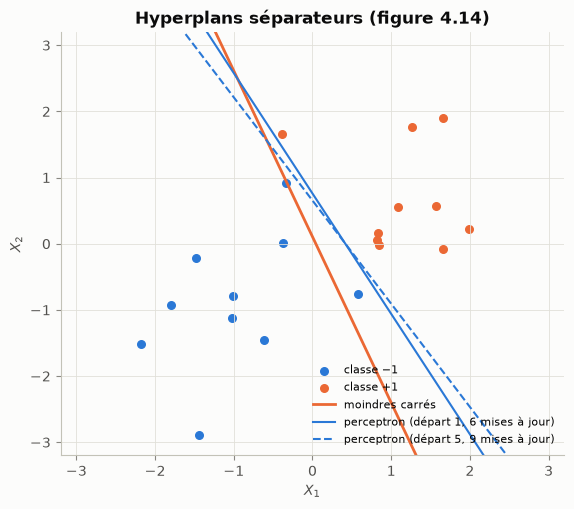

In [19]:
def droite(ax, b0, b, **kw):
    """Trace la droite {x : b0 + b^T x = 0} dans la fenêtre courante."""
    xs = np.array(ax.get_xlim())
    ax.plot(xs, -(b0 + b[0] * xs) / b[1], **kw)

lim_h = (-3.2, 3.2)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.set_xlim(lim_h)
ax.set_ylim(lim_h)
ax.scatter(*Xh[yh == -1].T, color=BLUE, s=30, label="classe $-1$")
ax.scatter(*Xh[yh == 1].T, color=ORANGE, s=30, label="classe $+1$")
droite(ax, b_ls[0], b_ls[1:], color=ORANGE, lw=2, label="moindres carrés")
for s, ls in [(1, "-"), (5, "--")]:
    r = c4.perceptron(Xh, yh, beta_init=np.random.RandomState(s).randn(3) * 3,
                      rng=np.random.RandomState(s))
    droite(ax, r["intercept"], r["coef"], color=BLUE, ls=ls, lw=1.5,
           label="perceptron (départ %d, %d mises à jour)" % (s, r["n_updates"]))
ax.set_title("Hyperplans séparateurs (figure 4.14)")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.legend(fontsize=8, loc="lower right")
plt.show()

### Géométrie d'un hyperplan (figure 4.15)

Soit $L = \{x : f(x) = \beta_0 + \beta^Tx = 0\}$. Trois propriétés élémentaires :

1. pour $x_1, x_2 \in L$, $\beta^T(x_1-x_2) = 0$ : le vecteur $\beta^* = \beta/\|\beta\|$
   est **normal** à $L$ ;
2. pour tout $x_0\in L$, $\beta^Tx_0 = -\beta_0$ ;
3. la **distance signée** d'un point $x$ à $L$ est la projection de $x - x_0$ sur $\beta^*$ :
   $$\beta^{*T}(x-x_0) = \frac{\beta^Tx - \beta^Tx_0}{\|\beta\|} = \frac{\beta^Tx+\beta_0}{\|\beta\|} = \frac{f(x)}{\|f'(x)\|}.$$

Ainsi $f(x)$ est **proportionnelle** à la distance signée de $x$ à l'hyperplan.

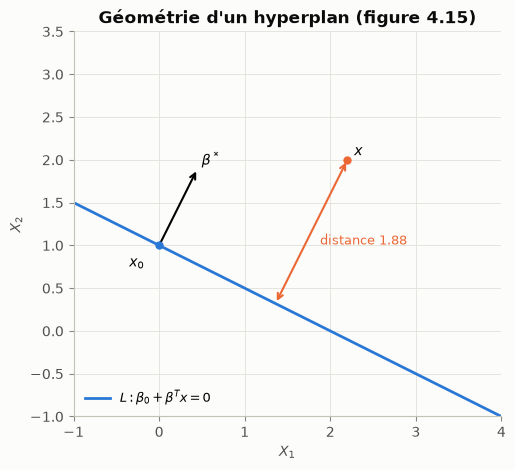

f(x)/||beta|| = 1.8783  ; distance euclidienne : 1.8783


In [20]:
beta_g, beta0_g = np.array([1.0, 2.0]), -2.0
x_pt = np.array([2.2, 2.0])
bstar = beta_g / np.linalg.norm(beta_g)
dist_signee = (beta_g @ x_pt + beta0_g) / np.linalg.norm(beta_g)
x_proj = x_pt - dist_signee * bstar                      # projeté orthogonal sur L
x0 = np.array([0.0, 1.0])                                # un point de L
fig, ax = plt.subplots(figsize=(6, 5))
ax.set_xlim(-1, 4)
ax.set_ylim(-1, 3.5)
droite(ax, beta0_g, beta_g, color=BLUE, label=r"$L : \beta_0 + \beta^T x = 0$")
ax.annotate("", xy=x_pt, xytext=x_proj, arrowprops=dict(arrowstyle="<->", color=ORANGE, lw=1.5))
ax.annotate("", xy=x0 + bstar, xytext=x0, arrowprops=dict(arrowstyle="->", color="k", lw=1.5))
ax.scatter(*x_pt, color=ORANGE, zorder=3)
ax.scatter(*x0, color=BLUE, zorder=3)
ax.text(*(x_pt + [0.08, 0.05]), "$x$")
ax.text(*(x0 + [-0.35, -0.25]), "$x_0$")
ax.text(*(x0 + bstar + [0.05, 0.05]), r"$\beta^*$")
ax.text(*((x_pt + x_proj) / 2 + [0.1, -0.15]), "distance %.2f" % dist_signee, color=ORANGE, fontsize=9)
ax.set_aspect("equal")
ax.set_title("Géométrie d'un hyperplan (figure 4.15)")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.legend(loc="lower left")
plt.show()
print("f(x)/||beta|| =", round(dist_signee, 4), " ; distance euclidienne :", round(np.linalg.norm(x_pt - x_proj), 4))

### Le perceptron de Rosenblatt (section 4.5.1)

Un point $x_i$ est mal classé si $y_i(\beta_0+\beta^Tx_i) < 0$. Le perceptron minimise la
somme des distances (au facteur $\|\beta\|$ près) des points mal classés à la frontière
(éq. (4.41)) :
$$D(\beta,\beta_0) = -\sum_{i\in\mathcal{M}} y_i(x_i^T\beta+\beta_0),$$
où $\mathcal{M}$ est l'ensemble des points mal classés. $D \ge 0$, et $D = 0$ exactement
quand aucun point n'est mal classé.

À $\mathcal{M}$ fixé, le gradient est (éq. (4.42)-(4.43))
$\partial D/\partial\beta = -\sum_{i\in\mathcal{M}}y_ix_i$ et
$\partial D/\partial\beta_0 = -\sum_{i\in\mathcal{M}}y_i$. Le perceptron effectue une
**descente de gradient stochastique** : au lieu de sommer sur tous les points mal classés,
il fait un pas après chaque point mal classé rencontré (éq. (4.44)) :
$$\begin{pmatrix}\beta\\ \beta_0\end{pmatrix} \leftarrow \begin{pmatrix}\beta\\ \beta_0\end{pmatrix} + \rho\begin{pmatrix}y_ix_i\\ y_i\end{pmatrix},$$
avec un pas $\rho$ que l'on peut prendre égal à 1 sans perte de généralité.

Si les classes sont séparables, l'algorithme s'arrête en un nombre **fini** d'étapes
(exercice 4.6). Mais (Ripley, 1996) :

1. la solution dépend du point de départ (nous l'avons vu) ;
2. le nombre d'étapes peut être très grand quand l'écart entre les classes est petit ;
3. si les données ne sont pas séparables, l'algorithme ne converge pas et des **cycles**
   apparaissent.

Illustrons les points 2 et 3. Pour le point 2, on fabrique des données séparables dont
la marge (distance du point le plus proche à l'hyperplan optimal) est contrôlée, et on
compte les mises à jour (moyenne sur 5 ordres de parcours).

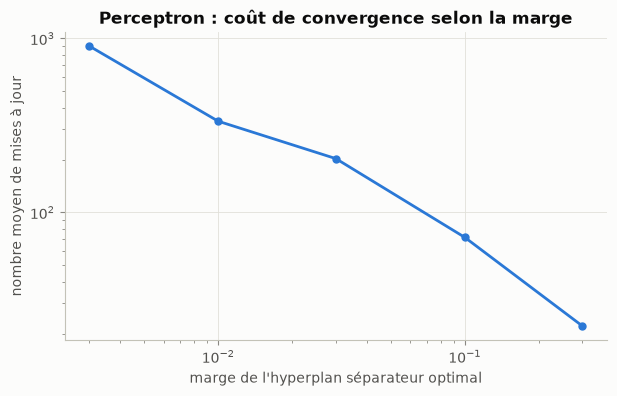

In [21]:
rng = np.random.RandomState(0)
w_g, w0_g = np.array([2.0, -1.0]), 0.3                  # droite génératrice 2 x1 - x2 + 0.3 = 0
U = rng.uniform(-1, 1, size=(90, 2))
s_bord = rng.uniform(-1, 1, 5)
P_bord = np.column_stack([s_bord, 2 * s_bord + w0_g])  # 5 points exactement sur la droite...
U = np.vstack([U, P_bord, P_bord])                     # ... présents dans les deux classes
yg = np.where(U @ w_g + w0_g > 0, 1, -1)
yg[-10:-5], yg[-5:] = 1, -1
ecarts = [0.3, 0.1, 0.03, 0.01, 0.003]
marges, nb_maj = [], []
for gap in ecarts:
    # on écarte chaque classe de « gap » le long de la normale : la marge optimale vaut gap
    Xg = U + gap * yg[:, None] * w_g / np.linalg.norm(w_g) + np.array([2.0, 2.0])
    marges.append(c4.optimal_hyperplane(Xg, yg)["margin"])
    nb_maj.append(np.mean([c4.perceptron(Xg, yg, max_epochs=200000, rng=np.random.RandomState(s))["n_updates"]
                           for s in range(5)]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(marges, nb_maj, "o-", color=BLUE)
ax.set_title("Perceptron : coût de convergence selon la marge")
ax.set_xlabel("marge de l'hyperplan séparateur optimal")
ax.set_ylabel("nombre moyen de mises à jour")
plt.show()

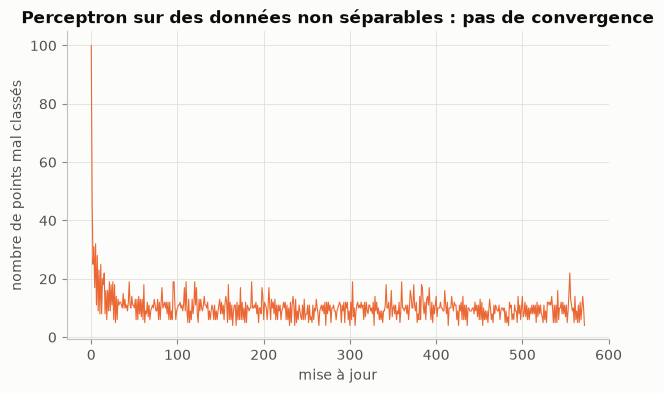

Convergé : False


In [22]:
yn = np.where(U[:, 0] + U[:, 1] + 0.3 * rng.randn(len(U)) > 0, 1, -1)   # données non séparables
r_ns = c4.perceptron(U, yn, max_epochs=60, rng=np.random.RandomState(0))
Za = np.column_stack([U, np.ones(len(U))])
n_err = [np.sum(yn * (Za @ bt) <= 0) for bt in r_ns["path"]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_err, color=ORANGE, lw=0.8)
ax.set_title("Perceptron sur des données non séparables : pas de convergence")
ax.set_xlabel("mise à jour")
ax.set_ylabel("nombre de points mal classés")
plt.show()
print("Convergé :", r_ns["converged"])